# Analyse Exploratoire

### Import des modules

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np

### Analyse Exploratoire

In [2]:
# On regarde comment le jeu de données est défini
df = pd.read_csv("./2016_Building_Energy_Benchmarking.csv")
df.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [3]:
# regarde les infos pour prendre connaissance du nombre de valeurs manquantes ainsi que le type 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

In [4]:
# Nombre de ligne dans le df :
print("Nombres de ligne :", len(df))

Nombres de ligne : 3376


In [5]:
# Déscription de chaques colonnes :
df.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,...,SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity
count,3376.000000,3376.0,3360.000000,3376.000000,3376.000000,3376.000000,3376.000000,3368.000000,3376.000000,3.376000e+03,...,3.371000e+03,3.370000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,0.0,3367.000000,3367.000000
mean,21208.991114,2016.0,98116.949107,4.439277,47.624033,-122.334795,1968.573164,1.106888,4.709123,9.483354e+04,...,5.403667e+06,5.276726e+06,2.745959e+05,1.086639e+06,3.707612e+06,1.368505e+04,1.368505e+06,NaN,119.723971,1.175916
std,12223.757015,0.0,18.615205,2.120625,0.047758,0.027203,33.088156,2.108402,5.494465,2.188376e+05,...,2.161063e+07,1.593879e+07,3.912173e+06,4.352478e+06,1.485066e+07,6.709781e+04,6.709781e+06,NaN,538.832227,1.821452
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,...,0.000000e+00,0.000000e+00,0.000000e+00,-3.382680e+04,-1.154170e+05,0.000000e+00,0.000000e+00,NaN,-0.800000,-0.020000
25%,19990.750000,2016.0,98105.000000,3.000000,47.599860,-122.350662,1948.000000,1.000000,2.000000,2.848700e+04,...,9.251286e+05,9.701822e+05,0.000000e+00,1.874229e+05,6.394870e+05,0.000000e+00,0.000000e+00,NaN,9.495000,0.210000
50%,23112.000000,2016.0,98115.000000,4.000000,47.618675,-122.332495,1975.000000,1.000000,4.000000,4.417500e+04,...,1.803753e+06,1.904452e+06,0.000000e+00,3.451299e+05,1.177583e+06,3.237538e+03,3.237540e+05,NaN,33.920000,0.610000
75%,25994.250000,2016.0,98122.000000,7.000000,47.657115,-122.319407,1997.000000,1.000000,5.000000,9.099200e+04,...,4.222455e+06,4.381429e+06,0.000000e+00,8.293178e+05,2.829632e+06,1.189033e+04,1.189034e+06,NaN,93.940000,1.370000
max,50226.000000,2016.0,98272.000000,7.000000,47.733870,-122.220966,2015.000000,111.000000,99.000000,9.320156e+06,...,8.739237e+08,4.716139e+08,1.349435e+08,1.925775e+08,6.570744e+08,2.979090e+06,2.979090e+08,NaN,16870.980000,34.090000


#### TERMINER L'ANALYSE EXPLORATOIRE 

A réaliser : 
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

Qelques pistes d'analyse : 

* Identifier les colonnes avec une majorité de valeurs manquantes ou constantes en utilisant la méthode value_counts() de Pandas
* Mettre en evidence les différences entre les immeubles mono et multi-usages
* Utiliser des pairplots et des boxplots pour faire ressortir les outliers ou des batiments avec des valeurs peu cohérentes d'un point de vue métier 

Pour vous inspirer, ou comprendre l'esprit recherché dans une analyse exploratoire, vous pouvez consulter ce notebook en ligne : https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python. Il ne s'agit pas d'un modèle à suivre à la lettre ni d'un template d'analyses attendues pour ce projet. 

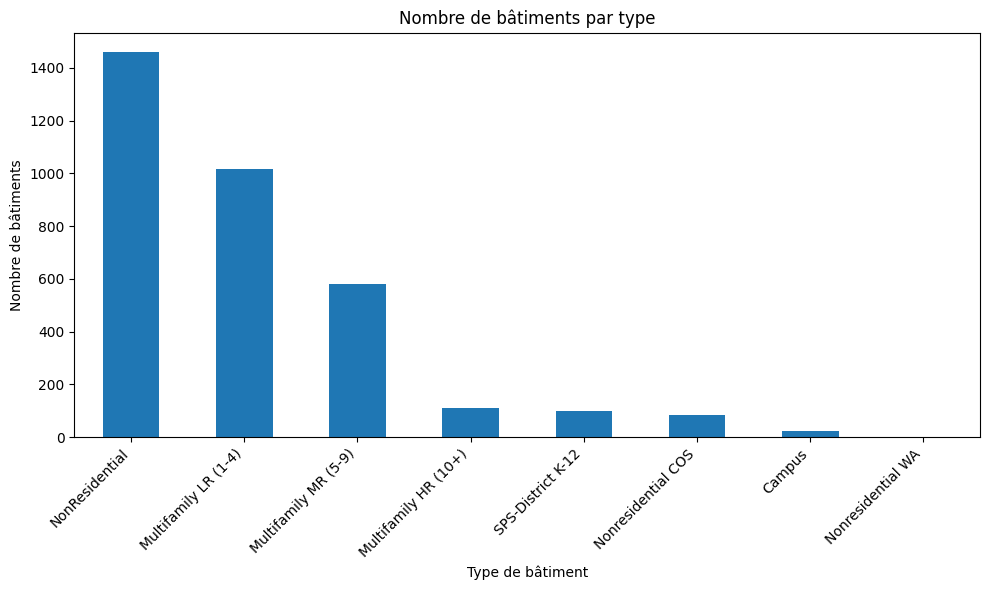

In [8]:
# Identification des types de batiments
building_counts = df['BuildingType'].value_counts()

plt.figure(figsize=(10, 6))
building_counts.plot(kind='bar')

plt.title("Nombre de bâtiments par type")
plt.xlabel("Type de bâtiment")
plt.ylabel("Nombre de bâtiments")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [9]:
# Je vais cibler les batiments non residentiel donc supprimer plusieurs lignes
df.drop(df[df['BuildingType']  == 'Multifamily LR (1-4)'].index, inplace=True)
df.drop(df[df['BuildingType']  == 'Multifamily MR (5-9)'].index, inplace=True)
df.drop(df[df['BuildingType']  == 'Multifamily HR (10+)'].index, inplace=True)

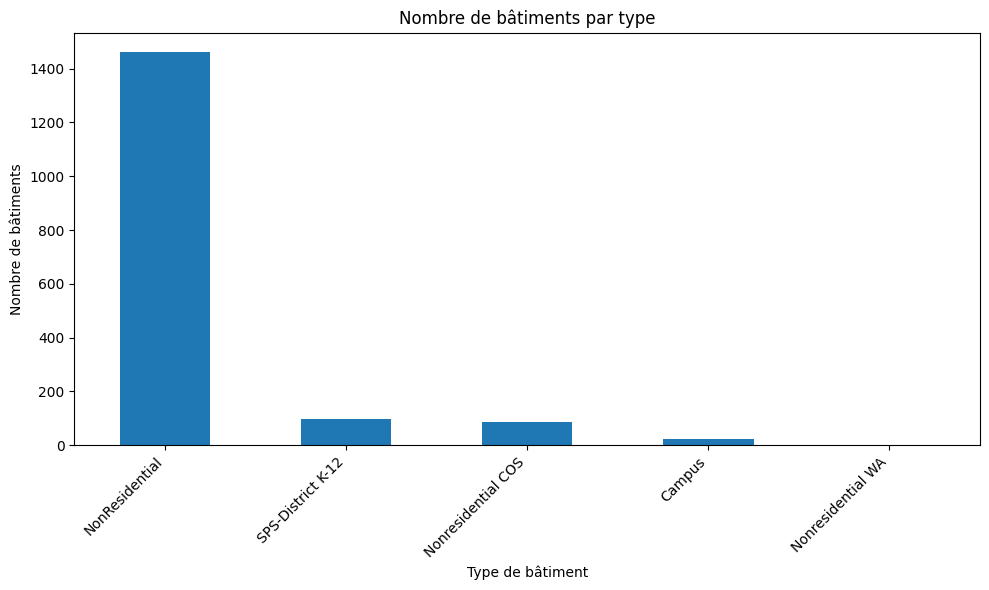

In [10]:
# Graphique après suppression des batiments 
building_counts = df['BuildingType'].value_counts()

plt.figure(figsize=(10, 6))
building_counts.plot(kind='bar')


plt.title("Nombre de bâtiments par type")
plt.xlabel("Type de bâtiment")
plt.ylabel("Nombre de bâtiments")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [12]:
# On va chercher les colonnes avec une valeur unique
unique_value_columns = [col for col in df.columns if df[col].nunique() == 1]

print("Colonnes avec valeur unique :")
for col in unique_value_columns:
    print(col)

Colonnes avec valeur unique :
DataYear
City
State



Colonnes avec >50% de valeurs manquantes :
YearsENERGYSTARCertified          0.941247
ThirdLargestPropertyUseType       0.788369
ThirdLargestPropertyUseTypeGFA    0.788369
dtype: float64


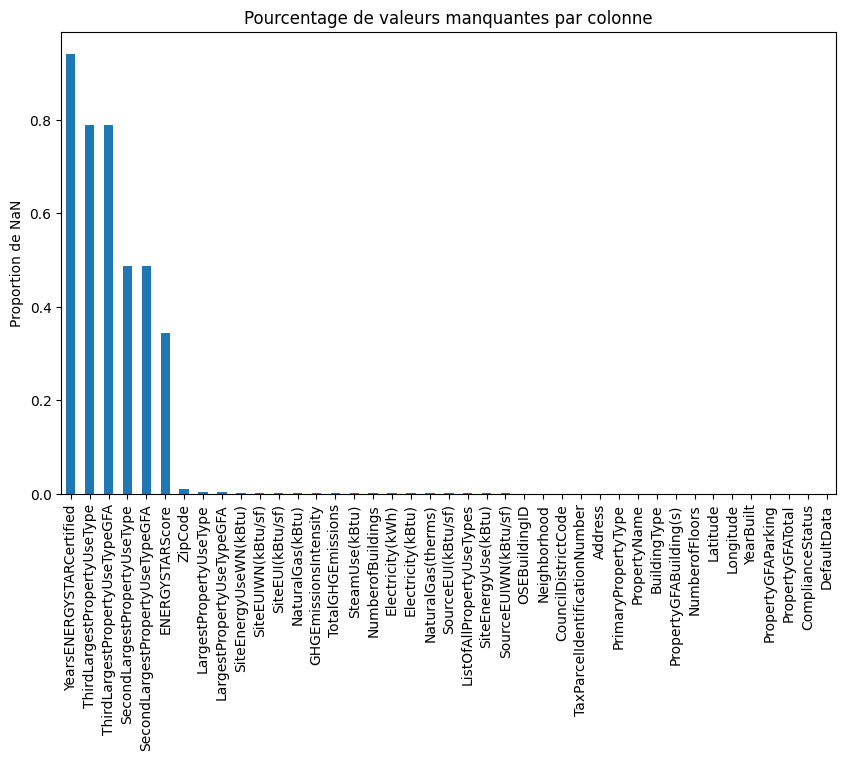

In [14]:
missing_ratio = df.isnull().mean().sort_values(ascending=False)
colonnes_a_forte_na = missing_ratio[missing_ratio > 0.5]
print("\nColonnes avec >50% de valeurs manquantes :")
print(colonnes_a_forte_na)

# Visualisation graphique des valeurs manquantes
plt.figure(figsize=(10,6))
missing_ratio.plot(kind='bar')
plt.title("Pourcentage de valeurs manquantes par colonne")
plt.ylabel("Proportion de NaN")
plt.show()

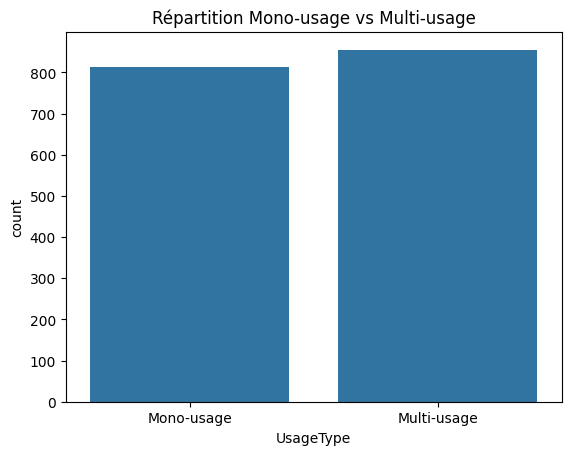

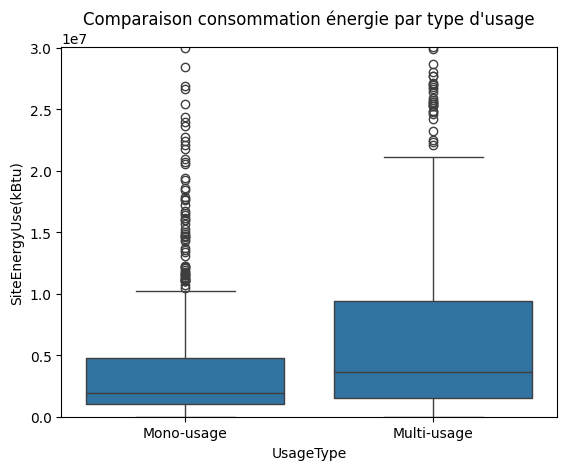

In [17]:
# Création d'une nouvelle variable : mono-usage ou multi-usage
df['UsageType'] = np.where(
    df['SecondLargestPropertyUseType'].notnull(), 'Multi-usage', 'Mono-usage'
)

# Comptage
sns.countplot(data=df, x='UsageType')
plt.title("Répartition Mono-usage vs Multi-usage")
plt.show()

# Comparaison consommation énergie
sns.boxplot(data=df, x='UsageType', y='SiteEnergyUse(kBtu)')
plt.ylim(0, df['SiteEnergyUse(kBtu)'].quantile(0.95))  # zoom pour éviter les extrêmes
plt.title("Comparaison consommation énergie par type d'usage")
plt.show()


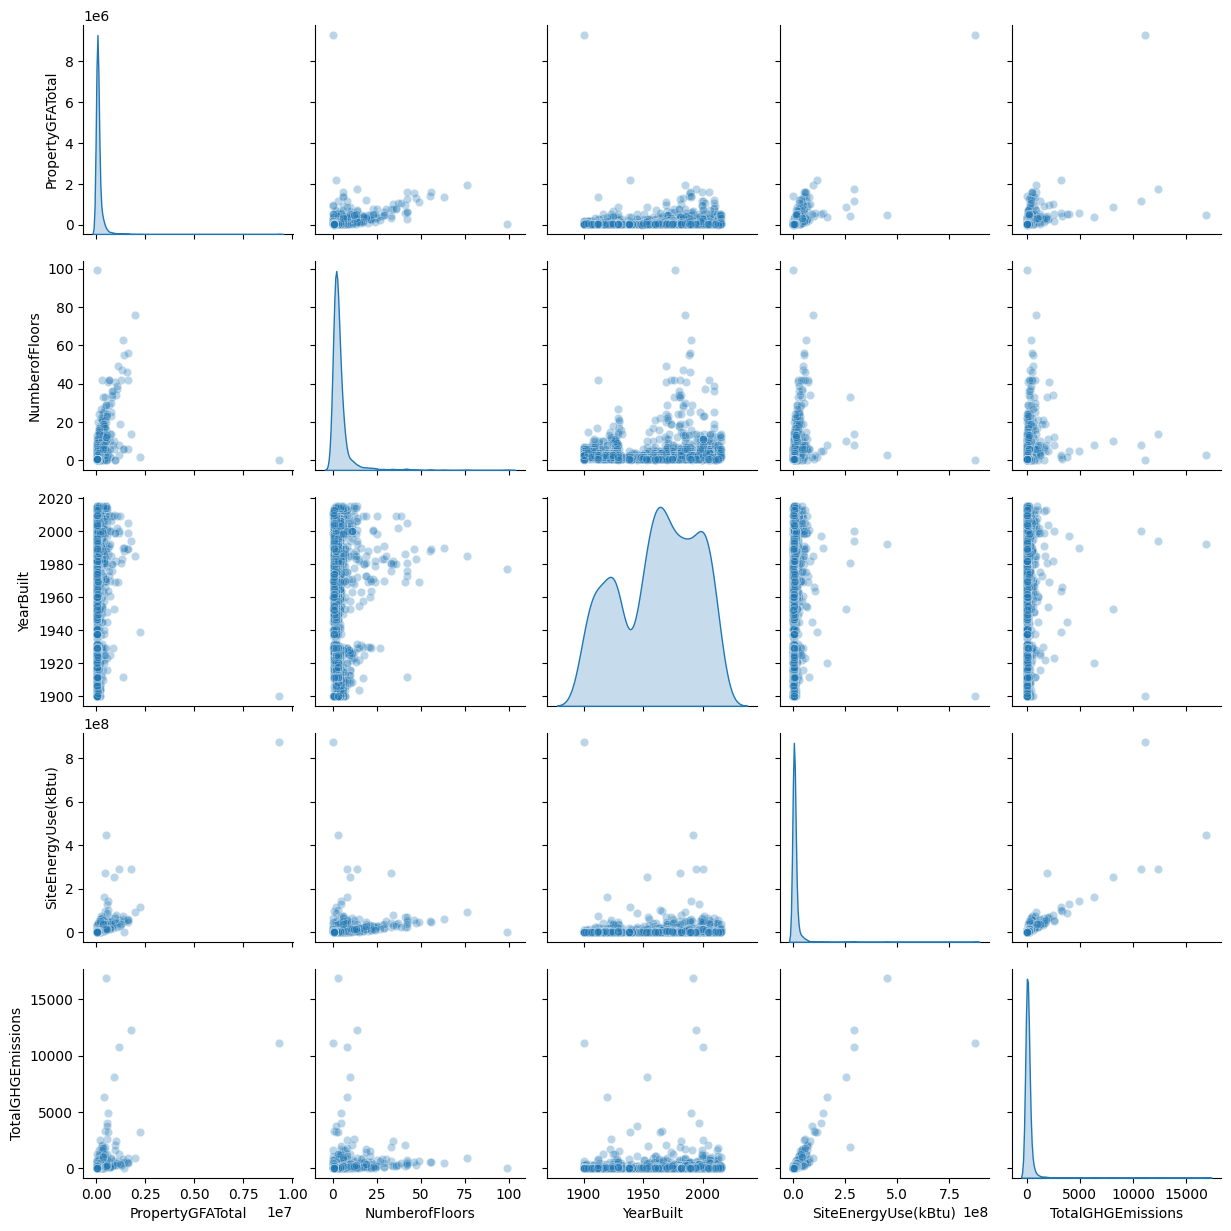

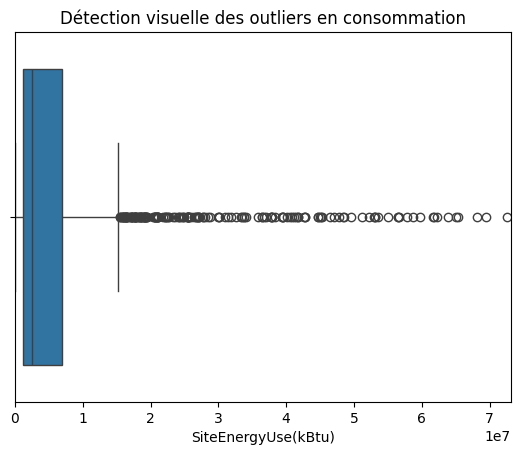

In [18]:
# Pairplot pour explorer quelques variables clés
vars_num = ['PropertyGFATotal', 'NumberofFloors', 'YearBuilt', 'SiteEnergyUse(kBtu)', 'TotalGHGEmissions']
sns.pairplot(df[vars_num], diag_kind="kde", plot_kws={'alpha':0.3})
plt.show()

# Boxplot pour la consommation
sns.boxplot(x=df['SiteEnergyUse(kBtu)'])
plt.xlim(0, df['SiteEnergyUse(kBtu)'].quantile(0.99))  # on limite l'échelle
plt.title("Détection visuelle des outliers en consommation")
plt.show()


In [20]:
# === ETAPE 7 : Création d'une version nettoyée du DataFrame ===

# Copie du DataFrame original pour garder une version "brute"
df_clean = df.copy()

# 1. Suppression des colonnes identifiants ou purement descriptives inutiles pour la modélisation
colonnes_a_supprimer = [
    'OSEBuildingID', 'PropertyName', 'Address', 'City', 'State',
    'TaxParcelIdentificationNumber', 'Comments'
]
df_clean.drop(columns=colonnes_a_supprimer, inplace=True, errors='ignore')

# 2. Suppression des colonnes constantes
colonnes_constantes = [col for col in df_clean.columns if df_clean[col].nunique() == 1]
df_clean.drop(columns=colonnes_constantes, inplace=True, errors='ignore')

# 3. Suppression des colonnes quasi vides (>80% de NaN)
missing_ratio = df_clean.isnull().mean()
colonnes_trop_vides = missing_ratio[missing_ratio > 0.8].index
df_clean.drop(columns=colonnes_trop_vides, inplace=True, errors='ignore')

# 4. Imputation simple des valeurs manquantes pour quelques variables clés
# - Numériques : médiane
colonnes_num = df_clean.select_dtypes(include=['float64', 'int64']).columns
for col in colonnes_num:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# - Catégorielles : mode
colonnes_cat = df_clean.select_dtypes(include=['object']).columns
for col in colonnes_cat:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# 5. Création de la variable "UsageType" (Mono / Multi)
df_clean['UsageType'] = np.where(
    df_clean['SecondLargestPropertyUseType'].notnull(), 'Multi-usage', 'Mono-usage'
)

# 6. Vérification finale
shape_before = df.shape
shape_after = df_clean.shape

shape_before, shape_after, df_clean.head()


((1668, 42),
 (1668, 37),
      BuildingType PrimaryPropertyType  ZipCode  CouncilDistrictCode  \
 0  NonResidential               Hotel  98101.0                    7   
 1  NonResidential               Hotel  98101.0                    7   
 2  NonResidential               Hotel  98101.0                    7   
 3  NonResidential               Hotel  98101.0                    7   
 4  NonResidential               Hotel  98121.0                    7   
 
   Neighborhood  Latitude  Longitude  YearBuilt  NumberofBuildings  \
 0     DOWNTOWN  47.61220 -122.33799       1927                1.0   
 1     DOWNTOWN  47.61317 -122.33393       1996                1.0   
 2     DOWNTOWN  47.61393 -122.33810       1969                1.0   
 3     DOWNTOWN  47.61412 -122.33664       1926                1.0   
 4     DOWNTOWN  47.61375 -122.34047       1980                1.0   
 
    NumberofFloors  ...  SteamUse(kBtu)  Electricity(kWh)  Electricity(kBtu)  \
 0              12  ...      2003882.0

In [23]:
df_clean.shape

(1668, 37)

In [ ]:
# Copie pour travail
df_model = df_clean.copy()

# 1. On conserve uniquement les lignes avec une target valide
df_model = df_model[df_model['SiteEnergyUse(kBtu)'].notnull()]

# 2. Suppression des colonnes entraînant un "data leakage"
cols = [
    'SiteEnergyUseWN(kBtu)', 'Electricity(kWh)', 'Electricity(kBtu)',
    'NaturalGas(therms)', 'NaturalGas(kBtu)', 'SteamUse(kBtu)',
    'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)'
]
df_model.drop(columns=[c for c in cols if c in df_model.columns], inplace=True)

# Suppression des colonnes texte inutiles
cols = [
    'OSEBuildingID', 'PropertyName', 'Address', 'City', 'State',
    'TaxParcelIdentificationNumber', 'Comments'
]

df_model.drop(columns=[c for c in cols if c in df_model.columns], inplace=True)

# Suppression colonnes à valeur unique
cols = [col for col in df_model.columns if df_model[col].nunique() <= 1]
df_model.drop(columns=const_cols, inplace=True)

# 5. Gestion des valeurs extrêmes sur la target
Q1 = df_model['SiteEnergyUse(kBtu)'].quantile(0.25)
Q3 = df_model['SiteEnergyUse(kBtu)'].quantile(0.75)
IQR = Q3 - Q1
limite_sup = Q3 + 1.5 * IQR
df_model = df_model[df_model['SiteEnergyUse(kBtu)'] <= limite_sup]

# 6. Gestion des valeurs manquantes restantes
# Numériques : médiane
num_cols = df_model.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    if df_model[col].isnull().sum() > 0:
        df_model[col] = df_model[col].fillna(df_model[col].median())

# Catégorielles : mode
cat_cols = df_model.select_dtypes(include=['object']).columns
for col in cat_cols:
    if df_model[col].isnull().sum() > 0:
        df_model[col] = df_model[col].fillna(df_model[col].mode()[0])

# 7. Encodage des variables catégorielles
df_model = pd.get_dummies(df_model, drop_first=True)

# 8. Résumé final
print("Shape final :", df_model.shape)
df_model.head()


Shape final : (1480, 511)


,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),...,ThirdLargestPropertyUseType_Retail Store,ThirdLargestPropertyUseType_Self-Storage Facility,ThirdLargestPropertyUseType_Social/Meeting Hall,ThirdLargestPropertyUseType_Strip Mall,ThirdLargestPropertyUseType_Supermarket/Grocery Store,ThirdLargestPropertyUseType_Swimming Pool,ThirdLargestPropertyUseType_Vocational School,ComplianceStatus_Error - Correct Default Data,ComplianceStatus_Missing Data,ComplianceStatus_Non-Compliant
0,98101.0,7,47.61220,-122.33799,1927,1.0,12,88434,0,88434,...,False,False,False,False,False,False,False,False,False,False
1,98101.0,7,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,...,False,False,False,False,False,False,False,False,False,False
3,98101.0,7,47.61412,-122.33664,1926,1.0,10,61320,0,61320,...,False,False,False,False,False,False,False,False,False,False
4,98121.0,7,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,...,False,False,False,False,False,True,False,False,False,False
5,98101.0,7,47.61623,-122.33657,1999,1.0,2,97288,37198,60090,...,False,False,False,False,False,False,False,False,False,False


# Modélisation 

### Import des modules 

In [25]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor


ModuleNotFoundError: No module named 'sklearn'

### Feature Engineering

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

In [ ]:
# CODE FEATURE ENGINEERING

### Préparation des features pour la modélisation

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

In [ ]:
# CODE PREPARATION DES FEATURES


### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [ ]:
# CODE COMPARAISON DES MODELES

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

In [ ]:
# CODE OPTIMISATION ET INTERPRETATION DU MODELE